<!-- m6:deber -->
# Módulo 6 · Deber — Detector bayesiano de fraude para PagoYa
**Diplomado en Big Data e Inteligencia Artificial · CEC-EPN** · Ing. Eduardo Avilés · individual · ≈ 3 horas

**Entrega:** Colab → **Archivo → Guardar (Ctrl+S)** → en *Repositorio* elija **el suyo** → ruta **`deber/deber.ipynb`** → mensaje `Deber`.
**Plazo: domingo 15-nov-2026, 11:00.** Un solo archivo: este cuaderno, ejecutado, con sus respuestas y el informe al final.

**Datos personalizados:** la API simulada genera transacciones **distintas para cada estudiante** a partir de su nombre. Sus cifras no coincidirán con las de sus compañeros; el docente puede regenerar sus datos para verificar.

| Parte | Tema | Puntos |
|---|---|---|
| 1 | Regresión logística bayesiana en PyMC (priors, muestreo y diagnóstico) | 20 |
| 2 | Comparación con boosting (XGBoost): discriminación y calibración | 20 |
| 3 | Modelo jerárquico por provincia | 20 |
| 4 | Decisión con matriz de costos e incertidumbre | 20 |
| 5 | Informe ejecutivo para el comité de riesgos | 20 |
| | **Total** | **100** |

**En cada parte:** código correcto y ejecutado (8) · resultados y diagnósticos (6) · interpretación propia (6).
Aquí no hay `___` para completar: el enunciado guía, **el código lo escribe usted** (puede reutilizar el de las clases 2 y 3).

## 0. Preparación

In [1]:
import importlib, subprocess, sys
for paquete in ['pymc']:
    if importlib.util.find_spec(paquete) is None:
        subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', paquete])
import os, urllib.request, warnings, logging
URL = 'https://raw.githubusercontent.com/JavyAviles/m6-ia-plantilla/main/curso.py'
if not os.path.exists('curso.py'):
    urllib.request.urlretrieve(URL, 'curso.py')
import curso
warnings.filterwarnings('ignore')
import numpy as np, pandas as pd, matplotlib.pyplot as plt
import pymc as pm
logging.getLogger('pymc').setLevel(logging.ERROR)
from sklearn.model_selection import train_test_split
from sklearn.metrics import roc_auc_score, brier_score_loss, balanced_accuracy_score
from xgboost import XGBClassifier
sigmoide = lambda z: 1 / (1 + np.exp(-z))
ba = lambda m, X_, y_: balanced_accuracy_score(y_, m.predict(X_))   # atajo: exactitud balanceada
print('Listo · curso', curso.VERSION)

Listo · curso m6-2026.11


**Escriba su nombre exactamente como en las clases ('Apellido Nombre').** Sus datos dependen de él.

In [2]:
NOMBRE = 'Estrella Danilo'                                               # ✏️ 'Apellido Nombre'
df = curso.datos_deber(NOMBRE)                               # datos personalizados + columna 'ratio'
df.head()

Huella de datos: Estrella Danilo · semilla 768867
Descargados 3006 eventos en 7 páginas de /v1/transacciones
Datos limpios: 2996 transacciones · tasa de fraude 10.01%


,evento_id,timestamp,id,edad,provincia,antiguedad_meses,ingreso_mensual,tipo,canal,categoria,monto,dispositivo_nuevo,distancia_km,intentos_pin,fraude,hora,ratio
0,TX-000000,2026-10-11 19:26:06-05:00,U0531,70.0,Pichincha,17,395.22,transferencia,app,persona,28.28,0,3.8,2,0,19,0.071555
1,TX-000001,2026-09-21 20:55:32-05:00,U0739,51.0,Manabí,2,1242.14,transferencia,app,persona,131.86,0,5.2,1,0,20,0.106156
2,TX-000002,2026-09-03 15:21:50-05:00,U0320,39.0,Pichincha,2,1295.64,pago_comercio,web,ropa,30.04,0,10.5,1,0,15,0.023185
3,TX-000003,2026-10-15 17:53:31-05:00,U0169,18.0,El Oro,22,1400.47,transferencia,app,persona,400.84,0,26.3,1,0,17,0.286218
4,TX-000004,2026-10-18 21:18:20-05:00,U0776,43.0,Azuay,39,377.89,pago_comercio,app,supermercado,39.30,0,0.4,3,1,21,0.103999


In [3]:
# Partición FIJA (no la cambie): 70 % entrenamiento, 30 % prueba, estratificada
cols = ['dispositivo_nuevo', 'distancia_km', 'ratio', 'intentos_pin', 'hora']
X_train, X_test, y_train, y_test = train_test_split(df[cols], df['fraude'], test_size=0.3,
                                                    stratify=df['fraude'], random_state=42)
print('Entrenamiento:', X_train.shape, '· Prueba:', X_test.shape, '· tasa de fraude:', round(df['fraude'].mean(), 4))

Entrenamiento: (2097, 5) · Prueba: (899, 5) · tasa de fraude: 0.1001


---
## Parte 1 · Regresión logística bayesiana en PyMC (20 pts)
1. **Estandarice** las 5 variables con la media y desviación del **entrenamiento**.
2. Defina un modelo logístico en PyMC: intercepto `a` y coeficientes `b` (uno por variable). **Elija y justifique las priors** (en la celda de texto).
3. Muestree con **4 cadenas**, `tune=1000`, 1000 muestras y `random_seed=42`.
4. Muestre la tabla `curso.diagnostico(...)` y verifique **R-hat ≤ 1,01** y **ESS > 400** en todos los parámetros.
5. Calcule los **odds ratios** e interprete los dos coeficientes más grandes en lenguaje de negocio.
6. Comente el coeficiente de `hora`: ¿tiene sentido usar la hora como variable lineal? (pista: madrugada).

In [4]:
# ✏️ Escriba aquí su modelo (estandarización, priors, muestreo con 4 cadenas y tabla de diagnóstico)
media, desv = X_train.mean(), X_train.std()                  # estandarizar con datos de ENTRENAMIENTO
Z = ((X_train - media) / desv).values

with pm.Model() as modelo_log:
    a = pm.Normal('a', mu=0, sigma=2)                         # prior del intercepto
    b = pm.Normal('b', mu=0, sigma=1, shape=len(cols))        # priors de los coeficientes (regularizan)
    pm.Bernoulli('obs', logit_p=a + pm.math.dot(Z, b), observed=y_train.values)
    tr_log = pm.sample(1000, tune=1000, chains=4, random_seed=42, progressbar=False)
diag = curso.diagnostico(tr_log, ['a', 'b']); diag.index = ['intercepto'] + cols
diag['odds_ratio'] = np.exp(diag['media']).round(2)           # efecto de +1 desviación estándar
diag




,media,desv,ic_3%,ic_97%,r_hat,ess,odds_ratio
intercepto,-3.0004,0.1176,-3.2269,-2.7830,1.0017,2633.0958,0.05
dispositivo_nuevo,0.7989,0.0666,0.6759,0.9262,1.0008,3295.6198,2.22
distancia_km,0.4338,0.0767,0.2903,0.5864,1.0006,3814.5204,1.54
ratio,0.9420,0.0758,0.8015,1.0889,1.0004,3448.6099,2.57
intentos_pin,0.5192,0.0690,0.3887,0.6519,1.0003,3680.9837,1.68
hora,-0.3597,0.0858,-0.5221,-0.1968,0.9996,3843.3159,0.70


In [5]:
from scipy.special import expit
from sklearn.metrics import roc_auc_score, brier_score_loss
import numpy as np

# medias posteriores
a_hat = tr_log.posterior['a'].mean().item()
b_hat = tr_log.posterior['b'].mean(dim=("chain", "draw")).values

# matriz de prueba estandarizada
Z_test = X_test[cols].values

# predictor lineal
eta = a_hat + Z_test @ b_hat

# probabilidades de fraude
p_log = expit(eta)

# métricas
auc_log = roc_auc_score(y_test, p_log)
brier_log = brier_score_loss(y_test, p_log)

print("AUC logística:", auc_log)
print("Brier logística:", brier_log)

AUC logística: 0.7451586320560363
Brier logística: 0.1164193964905629


**✍️ Respuesta:** _(escriba aquí su interpretación)_

Para el **intercepto** se utilizó una distribución normal centrada en cero a∼N(0,2). Esta elección refleja una posición inicial neutral, sin asumir de antemano que exista una alta o baja probabilidad de fraude, permitiendo que sean los datos los que determinen el nivel real de riesgo.

Para los **coeficientes** se emplearon distribuciones normales centradas en cero bj∼N(0,1). Estas priors asumen que, antes de observar los datos, las variables probablemente tengan efectos moderados sobre la probabilidad de fraude.

1. **Convergencia**

Todos los parámetros cumplen los criterios: R-hat ≤ 1.01 y ESS > 400, por lo que las estimaciones pueden considerarse confiables.

2. **Interpretación de los mayores odds ratios**

ratio (OR = 2.57): un aumento de una desviación estándar en esta variable multiplica por 2.57 las probabilidades de fraude.
dispositivo_nuevo (OR = 2.22): realizar una transacción desde un dispositivo nuevo multiplica por 2.22 las probabilidades de fraude.

3. **Variable hora**

La variable hora presenta un efecto negativo (OR = 0.70), pero modelarla de forma lineal puede no ser adecuado porque la hora es una variable cíclica: las 23:00 y las 00:00 están muy próximas, aunque sus valores numéricos sean muy distintos.

---
## Parte 2 · Comparación con boosting (20 pts)
1. Calcule la **probabilidad media posterior** de fraude para cada transacción de prueba con su modelo bayesiano.
2. Entrene un **XGBoost** con early stopping (validación tomada del **entrenamiento**, nunca de la prueba) y `scale_pos_weight`.
3. Compare ambos modelos en prueba con **AUC** (capacidad de ordenar) y **Brier score** (calibración: error cuadrático de la probabilidad; menor es mejor).
4. Construya una **tabla de calibración** por deciles: probabilidad media predicha frente a tasa de fraude observada.
5. Interprete: ¿cuál ordena mejor?, ¿cuál da probabilidades más confiables?, ¿por qué `scale_pos_weight` afecta la calibración?

In [6]:
# ✏️ Probabilidades del modelo bayesiano, XGBoost con early stopping, AUC, Brier y tabla de calibración

# Probabilidades del modelo bayesiano
# 1. Estandarizar conjunto de prueba
Z_test = ((X_test - media) / desv).values

# 2. Extraer muestras posteriores
a_post = tr_log.posterior['a'].values.flatten()
b_post = tr_log.posterior['b'].values.reshape(-1, len(cols))

# 3. Logit posterior para cada observación de prueba
logit_post = a_post[:, None] + b_post @ Z_test.T

# 4. Convertir a probabilidades
p_post = 1 / (1 + np.exp(-logit_post))

# 5. Probabilidad media posterior
p_media = p_post.mean(axis=0)

print(p_media[:5])      # primeras 5 probabilidades

resultado = pd.DataFrame({
    'fraude_real': y_test.values,
    'prob_fraude': p_media
})

resultado.head()




[0.06702966 0.07261454 0.09829106 0.02699534 0.01574807]


,fraude_real,prob_fraude
0,1,0.067030
1,0,0.072615
2,0,0.098291
3,0,0.026995
4,0,0.015748


In [7]:
X_tr, X_val, y_tr, y_val = train_test_split(
    X_train, y_train, test_size=0.2, stratify=y_train, random_state=42)   # validación SALE del entrenamiento
peso = (y_tr == 0).sum() / (y_tr == 1).sum()                # ~11 no fraudes por cada fraude
for lr in [0.3, 0.05]:                                      # dos tasas de aprendizaje
    m = XGBClassifier(n_estimators=1000, learning_rate=lr, max_depth=3, early_stopping_rounds=30,
                      scale_pos_weight=peso, eval_metric='logloss', random_state=42)
    m.fit(X_tr, y_tr, eval_set=[(X_val, y_val)], verbose=False)   # se detiene si 30 rondas no mejoran
    print(f'learning_rate={lr}: se detuvo en {m.best_iteration} árboles · exactitud balanceada {ba(m, X_test, y_test):.3f}')

learning_rate=0.3: se detuvo en 103 árboles · exactitud balanceada 0.846
learning_rate=0.05: se detuvo en 521 árboles · exactitud balanceada 0.867


In [8]:
from sklearn.metrics import roc_auc_score, brier_score_loss

p = m.predict_proba(X_test)[:, 1]

auc = roc_auc_score(y_test, p)
brier = brier_score_loss(y_test, p)

print("Mejor iteración:", m.best_iteration)
print("AUC:", auc)
print("Brier:", brier)

Mejor iteración: 521
AUC: 0.9125120175800028
Brier: 0.059432413253110494


In [9]:
# Tabla comparativa

import pandas as pd

print(
    f"Logística: AUC={auc_log:.4f}, Brier={brier_log:.4f}\n"
    f"XGBoost:   AUC={auc:.4f}, Brier={brier:.4f}"
)

Logística: AUC=0.7452, Brier=0.1164
XGBoost:   AUC=0.9125, Brier=0.0594


In [10]:
import pandas as pd

def tabla_calibracion(y, prob, nombre_modelo):

    df = pd.DataFrame({
        "y_real": y,
        "prob": prob
    })

    df["decil"] = pd.qcut(
        df["prob"],
        q=10,
        labels=range(1, 11),
        duplicates="drop"
    )

    tabla = (
        df.groupby("decil", observed=False)
          .agg(
              prob_media=("prob", "mean"),
              fraude_observado=("y_real", "mean"),
              n=("y_real", "size")
          )
          .round(4)
    )

    tabla.columns = pd.MultiIndex.from_product(
        [[nombre_modelo], tabla.columns]
    )

    return tabla

# Tablas individuales
tab_log = tabla_calibracion(y_test, p_log, "Logística")
tab_xgb = tabla_calibracion(y_test, p, "XGBoost")

# Comparación lado a lado
tabla_final = pd.concat([tab_log, tab_xgb], axis=1)

tabla_final

Logística                         XGBoost                     
      prob_media fraude_observado   n prob_media fraude_observado   n
decil                                                                
1         0.0001           0.0444  90     0.0034           0.0111  90
2         0.0005           0.0333  90     0.0099           0.0222  90
3         0.0011           0.0222  90     0.0173           0.0333  90
4         0.0028           0.0111  90     0.0268           0.0111  90
5         0.0066           0.0111  90     0.0400           0.0111  90
6         0.0134           0.1011  89     0.0610           0.0000  89
7         0.0312           0.1556  90     0.0995           0.0000  90
8         0.0790           0.1556  90     0.1902           0.0333  90
9         0.2562           0.2000  90     0.4551           0.1556  90
10        0.7857           0.2667  90     0.9194           0.7222  90

**✍️ Respuesta:**

XGBoost obtuvo un AUC de 0.9125 frente a 0.7452 de la regresión logística, por lo que presenta una capacidad significativamente superior para distinguir entre fraudes y no fraudes. Además, alcanzó un Brier Score de 0.0594, inferior al 0.1164 de la logística, indicando una mejor calidad global de las probabilidades predichas. La calibración propiamente dicha debe evaluarse mediante la tabla de calibración por deciles, comparando la probabilidad media predicha con la tasa de fraude observada en cada grupo.

El parámetro scale_pos_weight aumenta el peso de la clase minoritaria para mejorar su detección, pero puede afectar la calibración de las probabilidades al modificar la función de pérdida utilizada durante el entrenamiento.

---
## Parte 3 · Modelo jerárquico por provincia (20 pts)
1. Ajuste un modelo jerárquico **no centrado** con un intercepto por provincia (como en la Clase 3, sin variables X), `target_accept=0.99`, 4 cadenas.
2. Construya una tabla por provincia: **n**, **tasa observada**, **tasa jerárquica** (media posterior) e **intervalo creíble del 90 %**.
3. Reporte la media posterior de **sigma** e interprete.
4. ¿Qué provincias se «encogen» más hacia la media nacional y por qué?

In [11]:
# ✏️ Modelo jerárquico no centrado, tabla por provincia e interpretación de sigma
provincias = df['provincia'].astype('category')
idx, nombres = provincias.cat.codes.values, list(provincias.cat.categories)
with pm.Model() as modelo_jer:
    mu = pm.Normal('mu', mu=-2.4, sigma=1)                    # log-odds nacional (≈ 8 %)
    sigma = pm.HalfNormal('sigma', sigma=0.5)                 # cuánto difieren las provincias
    z = pm.Normal('z', 0, 1, shape=len(nombres))              # forma NO centrada
    a_prov = pm.Deterministic('a_prov', mu + sigma * z)
    pm.Bernoulli('obs', logit_p=a_prov[idx], observed=df['fraude'].values)
    tr_jer = pm.sample(1000, tune=1500, chains=4, random_seed=42, target_accept=0.99, progressbar=False)
tasas = sigmoide(tr_jer.posterior['a_prov'].values).reshape(-1, len(nombres))
#tabla = pd.DataFrame({'n': df.groupby('provincia').size(), 'tasa_observada': df.groupby('provincia')['fraude'].mean(),
#                      'tasa_jerarquica': pd.Series(tasas.mean(0), index=nombres)}).round(4)

ic_inf = np.percentile(tasas, 5, axis=0)
ic_sup = np.percentile(tasas, 95, axis=0)

tabla = pd.DataFrame({
    'n': df.groupby('provincia').size(),
    'tasa_observada': df.groupby('provincia')['fraude'].mean(),
    'tasa_jerarquica': pd.Series(tasas.mean(axis=0), index=nombres),
    'IC 90%': [
        f'[{li:.4f}, {ls:.4f}]'
        for li, ls in zip(ic_inf, ic_sup)
    ]
}).round(4)

tabla

,n,tasa_observada,tasa_jerarquica,IC 90%
Azuay,267,0.1011,0.1012,"[0.0833, 0.1209]"
El Oro,288,0.0729,0.0915,"[0.0683, 0.1099]"
Guayas,832,0.1034,0.1020,"[0.0887, 0.1170]"
Imbabura,132,0.1288,0.1078,"[0.0871, 0.1382]"
Loja,201,0.0746,0.0933,"[0.0690, 0.1129]"
Manabí,254,0.1299,0.1108,"[0.0909, 0.1395]"
Pichincha,888,0.0923,0.0963,"[0.0826, 0.1095]"
Tungurahua,134,0.1418,0.1112,"[0.0894, 0.1464]"


In [12]:
sigma = tr_jer.posterior['sigma'].values.flatten()

print(f"Media posterior: {sigma.mean():.4f}")
print(f"IC 90%: [{np.percentile(sigma,5):.4f}, "
      f"{np.percentile(sigma,95):.4f}]")

Media posterior: 0.1598
IC 90%: [0.0136, 0.3828]


In [13]:
tabla["diferencia"] = abs(
    tabla["tasa_observada"] - tabla["tasa_jerarquica"]
)

tabla.sort_values("diferencia", ascending=False)

,n,tasa_observada,tasa_jerarquica,IC 90%,diferencia
Tungurahua,134,0.1418,0.1112,"[0.0894, 0.1464]",0.0306
Imbabura,132,0.1288,0.1078,"[0.0871, 0.1382]",0.0210
Manabí,254,0.1299,0.1108,"[0.0909, 0.1395]",0.0191
Loja,201,0.0746,0.0933,"[0.0690, 0.1129]",0.0187
El Oro,288,0.0729,0.0915,"[0.0683, 0.1099]",0.0186
Pichincha,888,0.0923,0.0963,"[0.0826, 0.1095]",0.0040
Guayas,832,0.1034,0.1020,"[0.0887, 0.1170]",0.0014
Azuay,267,0.1011,0.1012,"[0.0833, 0.1209]",0.0001


**✍️ Respuesta:**

La media posterior de σ = 0.1598 indica una variación moderada entre provincias. Como el IC del 90% [0.0136, 0.3828] no incluye el cero, existe evidencia de que las tasas de fraude difieren entre provincias.

Las provincias que más se encogen hacia la media nacional son Tungurahua, Imbabura, Manabí, Loja y El Oro. El modelo jerárquico reduce las estimaciones extremas y las acerca a la media nacional (≈ 8%), especialmente cuando la evidencia provincial es más incierta. Por el contrario, provincias con mayor cantidad de observaciones, como Pichincha y Guayas, presentan un encogimiento mucho menor porque sus datos proporcionan información suficiente para estimar su tasa propia con mayor precisión.

---
## Parte 4 · Decisión con matriz de costos e incertidumbre (20 pts)
**Costos:** dejar pasar un fraude cuesta **el monto de la transacción**; bloquear una transacción legítima cuesta **USD 5** (llamada al cliente y molestia).
1. Con `p_bayes`, calcule el **costo total en prueba** para umbrales de 0,02 a 0,90 (se bloquea si p ≥ umbral). Grafique costo frente a umbral y elija el **umbral óptimo**.
2. Compare con dos políticas extremas: **no bloquear nada** y **bloquear todo**.
3. **Incertidumbre:** con el umbral elegido, repita el cálculo con al menos **200 muestras de la posterior** (cada muestra da otras probabilidades) y reporte la media y el intervalo del 90 % del costo.
4. *(Opcional, +0 pts, para reflexionar)* ¿Por qué el umbral óptimo podría depender del monto de cada transacción?

In [14]:
# ✏️ Función de costo, curva costo vs. umbral, políticas extremas y costo con 200 muestras de la posterior


import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

umbrales = np.arange(0.02, 0.91, 0.01)

resultados = []

for u in umbrales:

    # Se bloquea si p >= umbral
    bloqueada = (p_log >= u)

    # Falsos positivos: legítima bloqueada
    fp = ((y_test == 0) & bloqueada).sum()
    costo_fp = fp * 5

    # Falsos negativos: fraude no bloqueado
    fn_mask = ((y_test == 1) & (~bloqueada))
    # costo_fn = X_test.loc[fn_mask, "monto"].sum()
    costo_fn = df.loc[y_test.index[fn_mask], "monto"].sum()
    costo_total = costo_fp + costo_fn

    resultados.append([u, costo_fp, costo_fn, costo_total])

costos = pd.DataFrame(
    resultados,
    columns=["umbral", "costo_FP", "costo_FN", "costo_total"]
)

costos.head()


,umbral,costo_FP,costo_FN,costo_total
0,0.02,1425,2604.91,4029.91
1,0.03,1250,3202.76,4452.76
2,0.04,1145,3644.19,4789.19
3,0.05,1055,4647.77,5702.77
4,0.06,1000,4861.32,5861.32


Umbral óptimo: 0.02
Costo mínimo: 4,029.91


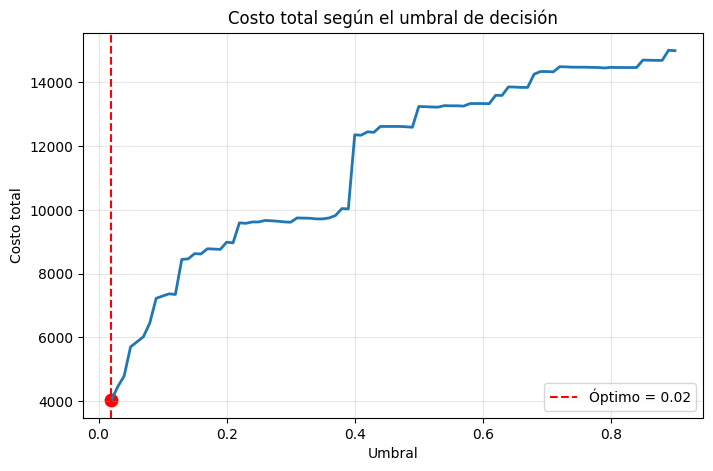

In [15]:
# Umbral óptimo
fila_optima = costos.loc[costos["costo_total"].idxmin()]

umbral_optimo = fila_optima["umbral"]
costo_minimo = fila_optima["costo_total"]

print(f"Umbral óptimo: {umbral_optimo:.2f}")
print(f"Costo mínimo: {costo_minimo:,.2f}")

# Gráfico
plt.figure(figsize=(8,5))
plt.plot(costos["umbral"], costos["costo_total"], lw=2)

plt.axvline(
    umbral_optimo,
    color="red",
    linestyle="--",
    label=f"Óptimo = {umbral_optimo:.2f}"
)

plt.scatter(
    umbral_optimo,
    costo_minimo,
    color="red",
    s=80
)

plt.xlabel("Umbral")
plt.ylabel("Costo total")
plt.title("Costo total según el umbral de decisión")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

In [16]:
# No bloquear nada

costo_no_bloquear = df.loc[y_test.index[y_test == 1], "monto"].sum()

print("Costo no bloquear nada:", costo_no_bloquear)

Costo no bloquear nada: 16976.850000000002


In [17]:
# Bloquear todo

fp_todo = (y_test == 0).sum()
costo_bloquear_todo = fp_todo * 5

print("Costo bloquear todo:", costo_bloquear_todo)

Costo bloquear todo: 4045


In [18]:
fila_optima = costos.loc[costos["costo_total"].idxmin()]

umbral_optimo = fila_optima["umbral"]
costo_optimo = fila_optima["costo_total"]

comparacion = pd.DataFrame({
    "Politica": ["No bloquear nada",
                 "Bloquear todo",
                 f"Modelo (u={umbral_optimo:.2f})"],
    "Costo": [costo_no_bloquear,
              costo_bloquear_todo,
              costo_optimo]
})

comparacion

,Politica,Costo
0,No bloquear nada,16976.85
1,Bloquear todo,4045.00
2,Modelo (u=0.02),4029.91


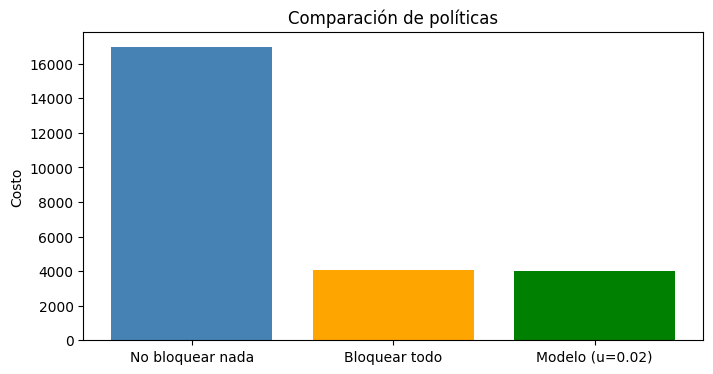

In [19]:
plt.figure(figsize=(8,4))

plt.bar(
    comparacion["Politica"],
    comparacion["Costo"],
    color=["steelblue", "orange", "green"]
)

plt.ylabel("Costo")
plt.title("Comparación de políticas")
plt.show()

In [20]:
# Combinar cadenas y draws
a_post = tr_log.posterior["a"].stack(sample=("chain", "draw")).values
b_post = tr_log.posterior["b"].stack(sample=("chain", "draw")).values.T

# Seleccionar 200 muestras aleatorias
rng = np.random.default_rng(42)
idx = rng.choice(len(a_post), size=200, replace=False)

# Recuperar el umbral óptimo
u_opt = costos.loc[costos["costo_total"].idxmin(), "umbral"]

# Calcular un costo por cada muestra posterior
monto_test = df.loc[y_test.index, "monto"]

costos_post = []

for i in idx:

    eta_i = a_post[i] + Z_test @ b_post[i]
    p_i = expit(eta_i)

    bloqueada = (p_i >= u_opt)

    fp = ((y_test == 0) & bloqueada).sum()
    costo_fp = fp * 5

    fn_mask = ((y_test == 1) & (~bloqueada))
    costo_fn = monto_test.loc[fn_mask].sum()

    costos_post.append(costo_fp + costo_fn)

costos_post = np.array(costos_post)

# Media e intervalo del 90 %
media = costos_post.mean()

li = np.percentile(costos_post, 5)
ls = np.percentile(costos_post, 95)

print(f"Costo medio = {media:,.2f}")
print(f"IC 90% = [{li:,.2f}, {ls:,.2f}]")


Costo medio = 2,621.15
IC 90% = [2,129.12, 3,095.37]


In [21]:
diag[['media','odds_ratio']]

,media,odds_ratio
intercepto,-3.0004,0.05
dispositivo_nuevo,0.7989,2.22
distancia_km,0.4338,1.54
ratio,0.9420,2.57
intentos_pin,0.5192,1.68
hora,-0.3597,0.70


In [22]:
from sklearn.metrics import roc_auc_score

auc_log = roc_auc_score(y_test, p_log)

print("AUC =", round(auc_log, 4))

from sklearn.metrics import brier_score_loss

brier_log = brier_score_loss(y_test, p_log)

print("Brier =", round(brier_log, 4))

AUC = 0.7452
Brier = 0.1164


**✍️ Respuesta:**

El umbral óptimo fue 0.02, lo que indica una política de bloqueo muy conservadora para minimizar las pérdidas por fraude. Con este umbral, el costo mínimo esperado es 4,029.91, muy inferior al de no bloquear nada (16,976.85), logrando un ahorro aproximado del 76 %.

Con el umbral óptimo, el costo esperado promedio es 2,621.15. Además, considerando la incertidumbre de los parámetros, existe un 90 % de probabilidad de que el costo real se sitúe entre 2,129.12 y 3,095.37. Esto sugiere que la estrategia es estable y que, incluso en escenarios menos favorables, el costo esperado se mantiene relativamente acotado.

El análisis de costos identificó un umbral óptimo de 0.02, con un costo esperado de 4,029.91. Este resultado mejora tanto la política de no bloquear ninguna transacción (16,976.85) como la de bloquear todas las transacciones (4,045.00). En particular, el uso del modelo permite ahorrar 12,946.94 unidades monetarias respecto a la estrategia de no intervención, lo que representa una reducción aproximada del 76.3 % del costo esperado. Aunque la mejora frente a bloquear todas las transacciones es modesta, el modelo logra reducir el costo total manteniendo una política de decisión más eficiente.

---
## Parte 5 · Informe ejecutivo (20 pts)
Para el **comité de riesgos** de PagoYa. Entre media y una página. Sin código: cifras de **sus** resultados.

### 1. Hallazgos
_(¿Qué variables explican el fraude? ¿Qué modelo ordena mejor y cuál está mejor calibrado? ¿Qué muestra el análisis por provincia?)_

### 2. Recomendación
_(Umbral recomendado, costo esperado e intervalo, ahorro frente a no hacer nada. ¿Qué modelo usaría en producción y para qué?)_

### 3. Limitaciones y riesgos
_(Datos simulados, variables faltantes, efecto no lineal de la hora, cambios de comportamiento del fraude, monitoreo necesario.)_


### 1. Hallazgos

El análisis realizado muestra que tanto la regresión logística bayesiana como XGBoost son capaces de identificar patrones asociados al fraude, aunque con niveles de desempeño diferentes. En la regresión logística, las variables más influyentes fueron el ratio (OR = 2.57), el uso de un dispositivo nuevo (OR = 2.22), el número de intentos de PIN (OR = 1.68) y la distancia de la transacción (OR = 1.54), todas asociadas a un incremento de la probabilidad de fraude. Por el contrario, la variable hora presentó un efecto protector (OR = 0.70), sugiriendo una menor incidencia de fraude en determinados horarios.

La comparación de modelos evidenció una clara superioridad de XGBoost. Este alcanzó un AUC de 0.9125 frente a 0.7452 de la regresión logística bayesiana, lo que indica una capacidad notablemente mayor para ordenar las transacciones según su riesgo de fraude. Además, obtuvo un Brier Score de 0.0594, inferior al 0.1164 de la regresión logística, demostrando que sus probabilidades predichas están mejor calibradas y representan con mayor precisión el riesgo real observado.

Finalmente, el análisis jerárquico por provincia evidenció diferencias geográficas en la incidencia del fraude. Las tasas jerárquicas más elevadas se observaron en Tungurahua (11.12 %), Manabí (11.08 %) e Imbabura (10.78 %), mientras que El Oro (9.15 %) y Loja (9.33 %) presentaron los niveles más bajos. Asimismo, las mayores correcciones entre las tasas observadas y las estimadas se registraron en provincias con menor tamaño muestral, lo que refleja el efecto de regularización del modelo jerárquico y proporciona estimaciones más robustas y estables.

En conjunto, los resultados indican que el fraude puede explicarse mediante variables de comportamiento y contexto de la transacción, que XGBoost constituye la mejor alternativa predictiva tanto en discriminación como en calibración, y que existen diferencias territoriales relevantes que podrían utilizarse para orientar estrategias de monitoreo y control más focalizadas.



### 2. Recomendación



Desde la perspectiva económica, el análisis de costos identificó un **umbral óptimo de 0.02**, valor que minimiza el costo esperado asociado a falsos positivos y falsos negativos. Con este umbral, el costo total esperado fue de **4,029.91**, inferior al observado bajo las estrategias extremas de **no bloquear ninguna transacción (16,976.85)** y **bloquear todas las transacciones (4,045.00)**. Esto supone un **ahorro de 12,946.94** respecto a la política de no intervención, equivalente a una reducción aproximada del **76.3 %** del costo esperado.


En un entorno de producción, **utilizaría XGBoost como modelo operativo para la detección y priorización de transacciones sospechosas**, debido a su mejor desempeño predictivo y calibración. Mantendría la **regresión logística bayesiana como herramienta complementaria de interpretación y análisis de riesgo**, ya que sus coeficientes permiten comprender y explicar los factores que influyen en la ocurrencia del fraude. De este modo, XGBoost aportaría la máxima capacidad predictiva para la decisión automática, mientras que el modelo bayesiano proporcionaría transparencia y soporte analítico para la gestión y supervisión del riesgo.





### 3. Limitaciones y riesgos

Los resultados deben interpretarse considerando varias limitaciones. En primer lugar, el análisis se realizó sobre datos simulados, por lo que los patrones identificados pueden no reflejar completamente el comportamiento observado en un entorno real. Aunque los datos permiten desarrollar y comparar metodologías de detección de fraude, su capacidad de generalización es necesariamente limitada.

En segundo lugar, el conjunto de variables disponibles puede no capturar todos los factores relevantes asociados al fraude. Variables adicionales relacionadas con el historial del cliente, características del comercio, dispositivos utilizados, ubicación detallada, patrones temporales o redes de relaciones entre transacciones podrían mejorar significativamente la capacidad predictiva de los modelos.

Asimismo, algunos efectos podrían ser más complejos de lo que reflejan los modelos utilizados. Por ejemplo, la relación entre la hora de la transacción y el riesgo de fraude podría ser no lineal, con franjas horarias específicas de mayor riesgo que no son adecuadamente representadas mediante un único coeficiente lineal. Métodos más flexibles, como árboles de decisión o modelos de aprendizaje automático, pueden capturar este tipo de comportamientos con mayor precisión.

Otro riesgo importante es el cambio en el comportamiento de los defraudadores a lo largo del tiempo. Las estrategias de fraude evolucionan continuamente en respuesta a los mecanismos de control implementados, lo que puede provocar una degradación progresiva del desempeño del modelo. Un modelo que presenta excelentes resultados en el período analizado podría perder capacidad predictiva si cambian los patrones operativos o aparecen nuevas modalidades de fraude.

Finalmente, cualquier modelo de detección de fraude requiere un proceso permanente de monitoreo, validación y recalibración. Se recomienda supervisar periódicamente métricas como AUC, Brier Score, tasas de falsos positivos, pérdidas económicas y distribución de variables clave, con el fin de detectar desviaciones tempranas y actualizar el modelo cuando sea necesario. Por tanto, los resultados obtenidos deben considerarse una herramienta de apoyo a la toma de decisiones y no un mecanismo definitivo o estático de detección de fraude.

